# Práctica 1: riesgo de impago en préstamos

## 0. Librerías y carga de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv("prestamos.csv")
print("Cargado el data frame con los siguentes datos ", df.shape)
df.head()


Cargado el data frame con los siguentes datos  (2645, 15)


,id_solicitud,fecha_solicitud,edad,ingresos_anuales,situacion_laboral,antiguedad_empleo_anios,vivienda,importe_solicitado,plazo_meses,finalidad,creditos_previos,impagos_previos,canal,gestion_recobro,impago
0,S-01477,2025-10-13,40.0,7474.0,Desempleado,0.0,Alquiler,13900.0,24,Consumo,2,1,Oficina,Sí,1
1,S-01166,2023-06-29,28.0,24852.0,Empleado,4.4,Con familia,9100.0,84,Coche,2,0,Oficina,No,0
2,S-01701,2023-06-15,55.0,NaN,Empleado,2.9,Alquiler,9850.0,84,Reforma,0,0,Oficina,No,0
3,S-01699,2023-12-22,49.0,28510.0,Empleado,1.9,Alquiler,6590.0,24,Consumo,2,0,Web,No,0
4,S-01201,2025-10-01,NaN,17555.0,Jubilado,NaN,Hipoteca,4470.0,60,Consumo,3,1,Oficina,No,0


La tabla tiene 2645 solicitudes y 15 columnas, una de las 15 columnas es el objetivo, es decir, la columna ["impago"]

## 3.1 Explorar los datos

In [2]:
print("Los datos para explorar son: ")

df.info()


Los datos para explorar son: 
<class 'pandas.DataFrame'>
RangeIndex: 2645 entries, 0 to 2644
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_solicitud             2645 non-null   str    
 1   fecha_solicitud          2645 non-null   str    
 2   edad                     2550 non-null   float64
 3   ingresos_anuales         2457 non-null   float64
 4   situacion_laboral        2645 non-null   str    
 5   antiguedad_empleo_anios  2313 non-null   float64
 6   vivienda                 2645 non-null   str    
 7   importe_solicitado       2645 non-null   float64
 8   plazo_meses              2645 non-null   int64  
 9   finalidad                2645 non-null   str    
 10  creditos_previos         2645 non-null   int64  
 11  impagos_previos          2645 non-null   int64  
 12  canal                    2645 non-null   str    
 13  gestion_recobro          2645 non-null   str    
 14  impag

Edad, ingresos_anuales, antiguedad_empleo_anios   tienen datos nulos, antiguedad de empleo es el que más tiene, casi el doble que ingresos anuales hay que seguir investigando. "fecha_solicitud" está en str cuando debería estar en formato "fecha"

In [3]:
nulos = df.isna().sum()
print("Los nulos son : \n", nulos)
porcentaje_nulos = (nulos / len(df) * 100).round(2) 
print("El porcentaje de nulos es : ")
print(porcentaje_nulos)

Los nulos son : 
 id_solicitud                 0
fecha_solicitud              0
edad                        95
ingresos_anuales           188
situacion_laboral            0
antiguedad_empleo_anios    332
vivienda                     0
importe_solicitado           0
plazo_meses                  0
finalidad                    0
creditos_previos             0
impagos_previos              0
canal                        0
gestion_recobro              0
impago                       0
dtype: int64
El porcentaje de nulos es : 
id_solicitud                0.00
fecha_solicitud             0.00
edad                        3.59
ingresos_anuales            7.11
situacion_laboral           0.00
antiguedad_empleo_anios    12.55
vivienda                    0.00
importe_solicitado          0.00
plazo_meses                 0.00
finalidad                   0.00
creditos_previos            0.00
impagos_previos             0.00
canal                       0.00
gestion_recobro             0.00
impago       

 Hay 3 columnas con nulos: En edad(3.59 por ciento), en ingresos anuales(7.11 por ciento) y en antigüedad_empleo_anios (12.55 por ciento), Esos 3 campos son los que hay que pensar en qué hacer con esos nulos y si imputar valores. No debería de borrar las filas con los nulos,  Los imputaré dentro del pipeline, después de partir los datos, para que la mediana se calcule solo con el entrenamiento

In [4]:
todos_dupli = df.duplicated().sum()
print("Los duplicados son: \n", todos_dupli)

Los duplicados son: 
 45


Tenemos 45 Duplicados, necesitamos saber de qué columna son, para ver si los podemos eliminar o si es que nos dan información extra

In [5]:
duplicados = df[df.duplicated(keep=False)].sort_values("id_solicitud")
display(duplicados.head(10))
duplicados.shape

,id_solicitud,fecha_solicitud,edad,ingresos_anuales,situacion_laboral,antiguedad_empleo_anios,vivienda,importe_solicitado,plazo_meses,finalidad,creditos_previos,impagos_previos,canal,gestion_recobro,impago
1499,S-00058,2025-04-14,34.0,20656.0,Empleado,10.6,Hipoteca,2120.0,48,Consumo,0,0,Web,No,0
1412,S-00058,2025-04-14,34.0,20656.0,Empleado,10.6,Hipoteca,2120.0,48,Consumo,0,0,Web,No,0
1809,S-00060,2025-01-05,33.0,7778.0,Desempleado,0.0,Alquiler,7610.0,12,Consumo,0,0,Web,Sí,1
1550,S-00060,2025-01-05,33.0,7778.0,Desempleado,0.0,Alquiler,7610.0,12,Consumo,0,0,Web,Sí,1
99,S-00195,2024-10-29,57.0,19954.0,Empleado,11.8,Propiedad,3450.0,12,Coche,3,0,Web,No,0
2090,S-00195,2024-10-29,57.0,19954.0,Empleado,11.8,Propiedad,3450.0,12,Coche,3,0,Web,No,0
1670,S-00331,2023-04-03,35.0,10405.0,Empleado,1.4,Alquiler,6070.0,12,Consumo,1,0,Web,Sí,1
372,S-00331,2023-04-03,35.0,10405.0,Empleado,1.4,Alquiler,6070.0,12,Consumo,1,0,Web,Sí,1
1947,S-00348,2024-07-19,53.0,16710.0,Funcionario,4.5,Propiedad,9400.0,60,Reforma,2,0,Oficina,No,0
934,S-00348,2024-07-19,53.0,16710.0,Funcionario,4.5,Propiedad,9400.0,60,Reforma,2,0,Oficina,No,0


(90, 15)

Salen 90 filas, cada id dos veces, son copias exactas

In [6]:
impagados = df["impago"].value_counts()
display(impagados)

impago
0    2388
1     257
Name: count, dtype: int64

In [7]:
df["impago"].value_counts(normalize=True)

impago
0    0.902836
1    0.097164
Name: proportion, dtype: float64

Prácticamente sin hacer nada el modelo tendría un 90,3 por ciento (accuracy) hay un 9,70 por ciento de impagados. Las clases entonces están muy desbalanceadas, hay muy pocos préstamos impagados y el que hay es muy importante acertarlo pero su recall es 0 %: no detecta ningún impago. Por eso no usaré la accuracy para elegir el modelo, sino el recall y la precisión.

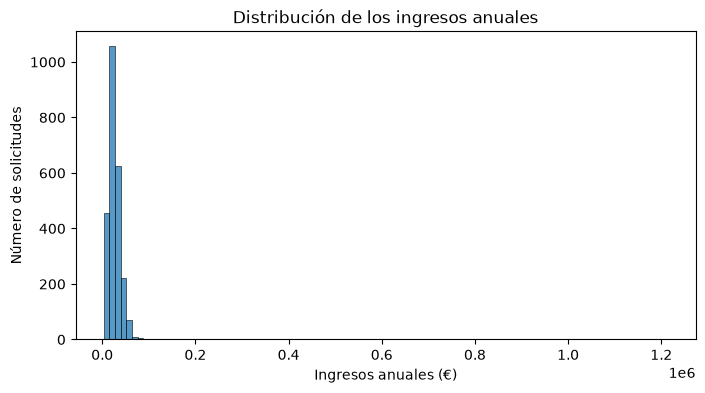

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="ingresos_anuales", ax=ax)
ax.set_title("Distribución de los ingresos anuales")
ax.set_xlabel("Ingresos anuales (€)")
ax.set_ylabel("Número de solicitudes")
plt.show()

In [9]:
display(df["ingresos_anuales"].sort_values(ascending=False).head(10))
df["ingresos_anuales"].describe().round(0)

1436    1213160.0
1926    1183800.0
35      1101920.0
1691    1021480.0
1919     381160.0
252       91341.0
311       89315.0
1150      85011.0
503       83082.0
474       79894.0
Name: ingresos_anuales, dtype: float64

count       2457.0
mean       27976.0
std        46836.0
min         3381.0
25%        17416.0
50%        24379.0
75%        32777.0
max      1213160.0
Name: ingresos_anuales, dtype: float64

In [10]:
df[df["ingresos_anuales"] > 300000]

,id_solicitud,fecha_solicitud,edad,ingresos_anuales,situacion_laboral,antiguedad_empleo_anios,vivienda,importe_solicitado,plazo_meses,finalidad,creditos_previos,impagos_previos,canal,gestion_recobro,impago
35,S-01016,2024-07-25,27.0,1101920.0,Autónomo,10.6,Propiedad,4170.0,12,Coche,0,0,Oficina,No,0
1436,S-02571,2025-07-30,63.0,1213160.0,jubilado,NaN,Alquiler,15930.0,24,Consumo,2,0,Gestor,No,0
1691,S-00070,2023-11-12,37.0,1021480.0,Empleado,2.6,Con familia,4430.0,24,Reforma,3,0,Web,No,0
1919,S-02427,2023-07-04,21.0,381160.0,Jubilado,NaN,Hipoteca,3050.0,24,Otros,3,0,Web,No,0
1926,S-02033,2023-05-07,44.0,1183800.0,Autónomo,9.2,Hipoteca,1670.0,48,Estudios,0,0,Oficina,No,0


### INTERPRETACIÓN DEL GRÁFICO 1

 La mayoría de los solicitantes gana entre 17416.0 y 32777 € al año(el 50 % central), y la mediana es 24379 €. Sin embargo, hay 4 valores por encima del millón y otro de 381160.0 €, muy separados del resto: después de ellos el siguiente valor es 91341 €. Sospecho que son erratas y no son millonarios reales porque al ver, el importe solicitado, su situación laboral y su finalidad, pues no es algo lógico para gente que gana más de 1 millón al año.
 
 Uno de ellos tiene 21 años y figura como jubilado, algo que es imposible.

Estos valores inflan la media (27976 €)  y la desviación típica (46.836€).
 
  Decidiré qué hacer con ellos en la limpieza.

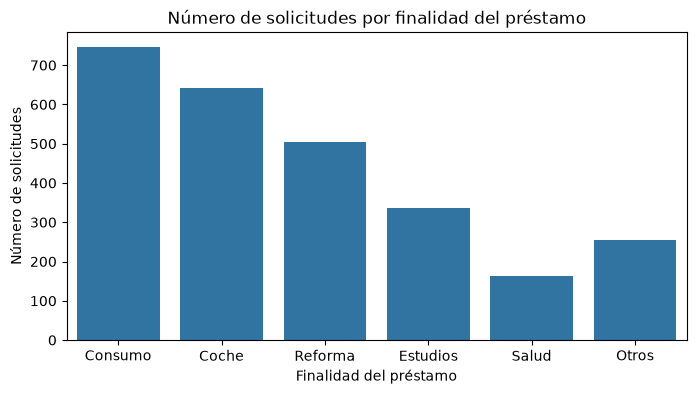

In [11]:
fig, ax = plt.subplots(figsize=(8,4))
sns.countplot(data=df, x="finalidad", ax=ax)
ax.set_title("Número de solicitudes por finalidad del préstamo")
ax.set_xlabel("Finalidad del préstamo")
ax.set_ylabel("Número de solicitudes")
plt.show()

### INTERPRETACIÓN DEL GRÁFICO 2

La mayoría de las solicitudes, son para consumo, coche, reforma o estudios, entre consumo y coche suma más de la mitad de las solicitudes, ninuna categoría es lo suficientemente pequeña como para dar problemas al modelo. No creo que aquí necesite limpieza.

In [12]:
df["finalidad"].value_counts(normalize=True).round(2)

finalidad
Consumo     0.28
Coche       0.24
Reforma     0.19
Estudios    0.13
Otros       0.10
Salud       0.06
Name: proportion, dtype: float64

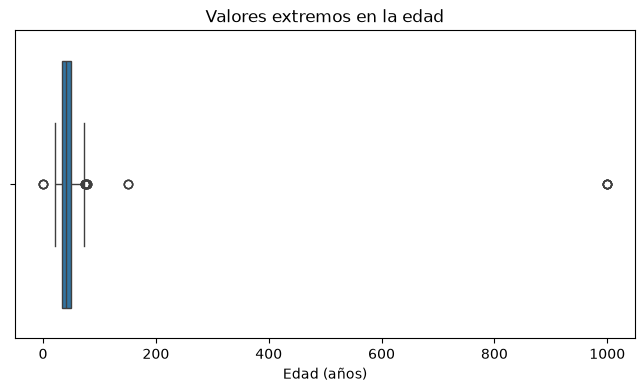

In [13]:
fig, ax = plt.subplots(figsize=(8,4))
sns.boxplot(data=df, x="edad", ax=ax)
ax.set_title("Valores extremos en la edad")
ax.set_xlabel("Edad (años)")
plt.show()

In [14]:
display(df["edad"].describe().round(1))
extremos_edad = df[(df["edad"] < 18) | (df["edad"] > 75)]
extremos_edad["edad"].value_counts().sort_index()

count    2550.0
mean       43.4
std        48.0
min         0.0
25%        33.0
50%        41.0
75%        49.0
max       999.0
Name: edad, dtype: float64

edad
0.0      4
76.0     1
78.0     4
150.0    3
999.0    6
Name: count, dtype: int64

### INTERPRETACIÓN DEL GRÁFICO 3



La mitad central de los solicitantes tiene entre 33 y 49 años y la mediana es de 41 años. Los bigotes llegan aproximadamente de los 21 a los 73 años, que son edades razonables para pedir un préstamo.

0 años (4 casos), 150 años (3) y 999 años (6): son valores imposibles. Son errores y en la limpieza los convertiré en nulos para que imputen como el resto.

76 y 78 años (5 casos) Son rarezas, pero puede ser real el valor, porque son jubilados, los mantendré 



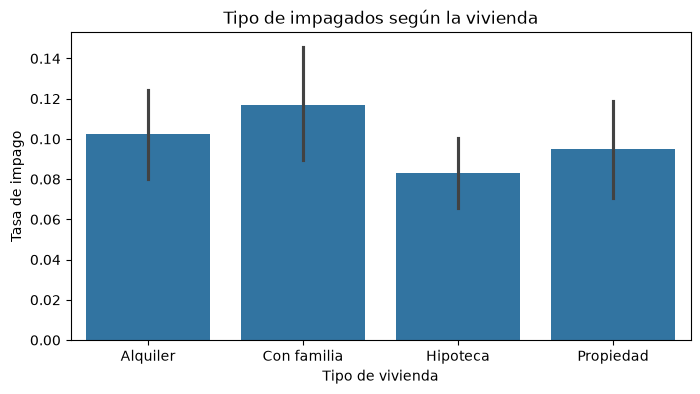

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, x="vivienda", y="impago", ax=ax)
ax.set_title("Tipo de impagados según la vivienda")
ax.set_xlabel("Tipo de vivienda")
ax.set_ylabel("Tasa de impago")
plt.show()

In [16]:
df.groupby("vivienda")["impago"].mean().round(3)

vivienda
Alquiler       0.102
Con familia    0.117
Hipoteca       0.083
Propiedad      0.095
Name: impago, dtype: float64

### INTEPRETACIÓN 4 GRÁFICO

La tasa de impago cambia algo según el tipo de vivienda, los que vive con familia son los que más impagan, los que tienen hipoteca son los que menos impagan, aun así son diferencias muy pequeñas, la vivienda parece ser una variable poco definitiva con respecto al impago, la voy a mantener en el modelo

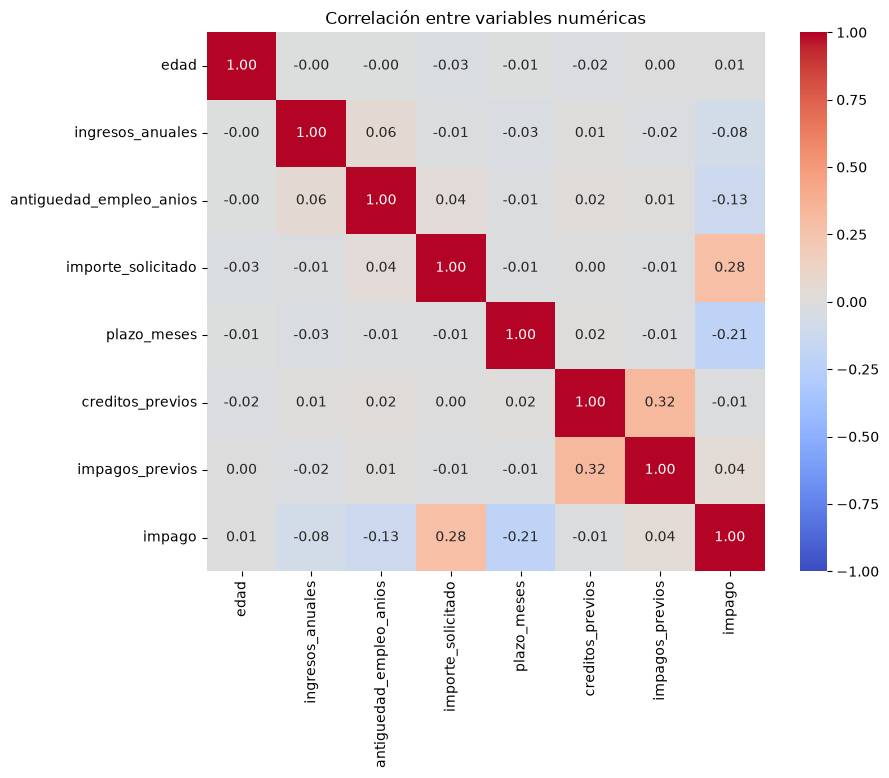

In [17]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.select_dtypes("number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",vmin=-1, vmax=1, ax=ax) 
ax.set_title("Correlación entre variables numéricas")
plt.show()


### INTERPRETACIÓN GRÁFICO 5

Impago tiene una correlación media con importe solicitado (0,28) cosa que tiene sentido, ya que al pedir más importe es más difícil devolverlo, con plazo meses tiene un -0,21, también tiene sentido, ya que al tener más meses, la cuota mensual es más baja, lo que me sorprende mucho es la baja correlación con impagos_previos(0,04), ya que uno espera que quien ya impagó vuelva a hacerlo

Ninguna correlación con impago es fuerte (todas con menos de 0,3), eso quiere decir que ninguna variable predice bien el impago, el modelo tendrá que combinarlas, además la correlación solo mide relaciones lineales y solo entre variables numéricas.

In [18]:
situacion = df["situacion_laboral"].str.strip().str.capitalize()
nulo_antig = df["antiguedad_empleo_anios"].isna()
nulo_antig.groupby(situacion).mean().round(3)

situacion_laboral
Autónomo       0.037
Desempleado    0.033
Empleado       0.044
Funcionario    0.050
Jubilado       1.000
Name: antiguedad_empleo_anios, dtype: float64

In [19]:
nulo_antig.groupby(df["impago"]).mean().round(3)



impago
0    0.126
1    0.117
Name: antiguedad_empleo_anios, dtype: float64

## 3.2 limpiar los datos 

In [20]:
df = df.drop_duplicates()
print("Filas después de quitar duplicados: ", df.shape)

Filas después de quitar duplicados:  (2600, 15)


 Elimino los 45 duplicados porque son copias exactas (mismo id y mismos datos) no aportan información y harían que el modelo diera más peso a esas solicitudes.

In [21]:
print("Antes: ", df["situacion_laboral"].nunique(), "categorias")

df["situacion_laboral"] = df["situacion_laboral"].str.strip().str.capitalize()

print("Después: ", df["situacion_laboral"].nunique(),"categorias")
df["situacion_laboral"].value_counts()

Antes:  25 categorias
Después:  5 categorias


situacion_laboral
Empleado       1448
Autónomo        394
Funcionario     295
Desempleado     237
Jubilado        226
Name: count, dtype: int64

La columna tenía 25 formas distintas de escribir solo 5 situaciones ("EMPLEADO", " Empleado", "empleado "...). Para el modelo serían categorías diferentes, así que quito los espacios y dejo solo la primera letra en mayúscula.

In [ ]:
imposibles = (df["edad"] < 18) | (df["edad"] > 100)
print("Edades imposibles: ", imposibles.sum())

df.loc[imposibles, "edad"] = np.nan
print("Nulos en edad ahora: ", df["edad"].isna().sum())

Edades imposibles:  13
Nulos en edad ahora:  103


Las edades de 0, 150 y 999 son errores. No borramos las filas, porque el resto de sus datos sirve. Solo vaciamos la edad (la ponemos como nulo) y el pipeline la rellenará después con la mediana, igual que los demás nulos.

In [26]:
ingresos_raros = (df["ingresos_anuales"] > 300000)
display(ingresos_raros.sum())
df.loc[ingresos_raros, "ingresos_anuales"] = np.nan
print("nulos en ingresos ahora: ", df["ingresos_anuales"].isna().sum())

np.int64(5)

nulos en ingresos ahora:  190


Los 5 ingresos de más de 300 000 € son casi seguro errores: piden préstamos pequeños y uno es un jubilado de 21 años. No borro las filas,2d convierto esos ingresos en nulos y el pipeline los rellenará con la mediana